### 1. Tìm hiểu dữ liệu của Amazon Reviews Dataset

In [ ]:
# Đọc dữ liệu bằng Pandas
import pandas as pd

train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

print(train_df.head())
print(train_df.info())
print(train_df.shape)
print(train_df.columns)

                                         review_text     label
0  But I haven't received it yet since ordering i...  negative
1  Well written articles, good start up info as w...  positive
2  Love this magazine, I always find a few things...  positive
3  I have read this magazine since I was a teen.....  positive
4  don't feel like supporting a racist woman who ...  negative
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_text  1000 non-null   str  
 1   label        1000 non-null   str  
dtypes: str(2)
memory usage: 15.8 KB
None
(1000, 2)
Index(['review_text', 'label'], dtype='str')


In [ ]:
#Kiểm tra xem có dữ liệu thiếu hay không
print(train_df.isnull().sum())
print(train_df.duplicated().sum())

review_text    0
label          0
dtype: int64
0


In [ ]:
# Kiểm tra phân bố nhãn
print(train_df["label"].value_counts())
print(train_df["label"].value_counts(normalize=True) * 100)

label
positive    553
negative    447
Name: count, dtype: int64
label
positive    55.3
negative    44.7
Name: proportion, dtype: float64


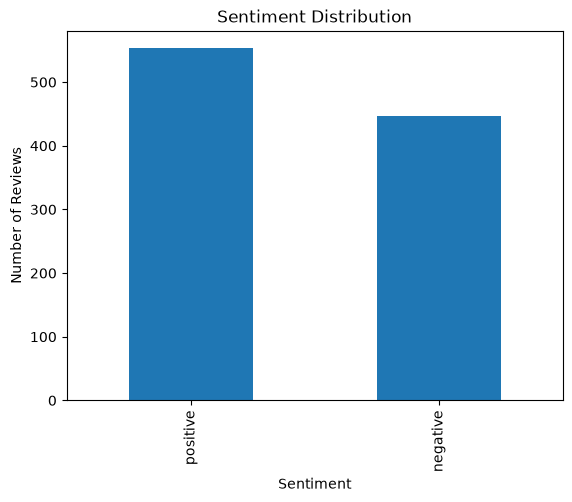

In [ ]:
# vẽ biểu đồ về phân bố nhãn
import matplotlib.pyplot as plt

train_df["label"].value_counts().plot(
    kind="bar",
    title="Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
# Phân tích độ dài bình luận
train_df["text_length"] = train_df["review_text"].str.len()

print(train_df["text_length"].describe())

count    1000.000000
mean       92.925000
std        47.386061
min         9.000000
25%        49.000000
50%        97.000000
75%       132.000000
max       179.000000
Name: text_length, dtype: float64


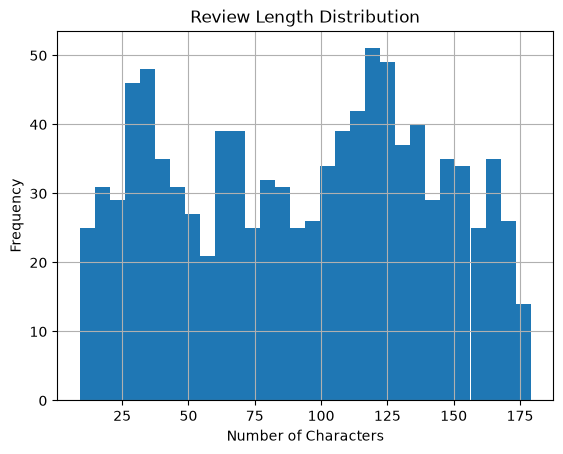

In [ ]:
# Vẽ biểu đồ về độ dai bình luận
train_df["text_length"].hist(bins=30)

plt.title("Review Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

### 2. Tiền xử lý dữ liệu

In [ ]:
# Làm sạch văn bản
import re

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_df["review_text"] = (
    train_df["review_text"].apply(clean_text)
)

In [ ]:
# Kiểm tra số lượng bản ghi sau khi làm sạch

# Kiểm tra kích thước dữ liệu
print("Kích thước dữ liệu:", train_df.shape)

# Kiểm tra số lượng dòng
print("Số lượng bản ghi:", len(train_df))

# Kiểm tra dữ liệu bị thiếu
print("\nDữ liệu thiếu:")
print(train_df.isnull().sum())

# Kiểm tra dữ liệu trùng lặp
print("\nSố lượng bản ghi trùng lặp:",
      train_df.duplicated().sum())

Kích thước dữ liệu: (1000, 3)
Số lượng bản ghi: 1000

Dữ liệu thiếu:
review_text    0
label          0
text_length    0
dtype: int64

Số lượng bản ghi trùng lặp: 0


In [ ]:
# Kiểm tra phân bố nhãn cảm xúc

# Đếm số lượng từng nhãn
print(train_df["label"].value_counts())

# Tính tỷ lệ phần trăm
print(train_df["label"].value_counts(normalize=True) * 100)

label
positive    553
negative    447
Name: count, dtype: int64
label
positive    55.3
negative    44.7
Name: proportion, dtype: float64


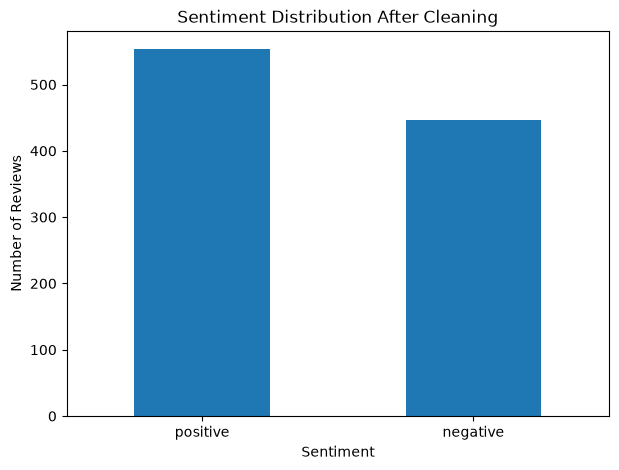

In [ ]:
# Vẽ biểu đồ phân bố sau khi làm sạch
import matplotlib.pyplot as plt

# Đếm số lượng từng nhãn
label_counts = train_df["label"].value_counts()

# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

label_counts.plot(
    kind="bar",
    title="Sentiment Distribution After Cleaning"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# tổng hợp bảng so sánh trước và sau khi làm sạch

# Lưu số lượng bản ghi ban đầu
original_count = len(train_df)

# Làm sạch dữ liệu
train_df["review_text"] = train_df["review_text"].apply(clean_text)

# Xóa review rỗng
train_df = train_df[
    train_df["review_text"].notna() &
    (train_df["review_text"].str.strip() != "")
]

# Xóa bản ghi trùng lặp
train_df = train_df.drop_duplicates()

# Reset index
train_df = train_df.reset_index(drop=True)

# Tổng hợp kết quả
cleaned_count = len(train_df)

print("Số bản ghi ban đầu:", original_count)
print("Số bản ghi sau làm sạch:", cleaned_count)
print("Số bản ghi đã loại bỏ:", original_count - cleaned_count)

Số bản ghi ban đầu: 1000
Số bản ghi sau làm sạch: 1000
Số bản ghi đã loại bỏ: 0


In [ ]:
# Lưu kết quả tiền xử lý dữ liệu vào file riêng
train_df.to_csv("../data/processed_train.csv", index=False)